# Part 1 · Notebook 3: The model in the real world

**Goal:** measure how the model of [notebook 2](02_eurosat_models.ipynb) (98.98 % on EuroSAT) behaves on new
Sentinel-2 images, sent through the API as a user would.

| Level | What changes | Balanced accuracy | Patches |
|---|---|---|---|
| 0 | Nothing: EuroSAT test set | 99.4 % | 5,400 |
| 1 | The date: Marne, summer 2025, Level-1C | **96.6 %** | 285 |
| 2 | The season: spring / autumn / winter | 96.6 / 95.5 / 93.7 % | 230–284 |
| 3 | The product: same patches, **Level-2A** | **44.6 %** | 285 |
| 4 | The region: Morocco, summer, Level-1C | **71.6 %** | 162 |

**Key findings**

- New dates and seasons cost 3 to 6 points.
- Level-2A, the most common Sentinel-2 product, halves the score: every forest becomes a crop field.
- In Morocco, most of the drop is a label effect: the map calls orchards "forest". Without that group, the
  score is 95.4 %.

## How the test works

New 2025 images are cut into 640 m patches and labelled from independent maps: the RPG (French farm plots)
and ESA WorldCover (forest, water, built-up). Level-1C comes from Copernicus Data Space, Level-2A from
Planetary Computer; levels 1 and 3 use the same acquisition. The maps cannot separate a lake from a river or
houses from factories, so the 10 classes are scored as 5 groups: Crop, Grass, Forest, Water, Built-up. A patch
is kept when one class covers at least 70 % of it and it has no cloud.

## What this test can and cannot measure

- **Size.** 447 patches. Some groups are small (16 Built-up patches in France, 6 in Morocco), so their scores
  are uncertain.
- **Missing classes.** No PermanentCrop or Pasture in France (the vineyards are not in the RPG, pasture is
  rare), and no source for Highway or HerbaceousVegetation.
- **Label issues.** The maps have errors (WorldCover is about 77 % accurate) and their own definitions:
  WorldCover's "tree cover" includes orchards and scattered trees, while EuroSAT's Forest is dense forest.
  WorldCover dates from 2021, and up to 30 % of a patch can be something else, such as a road.
- **Missed clouds.** The cloud mask misses some thin clouds, mostly in winter and autumn.

These factors mostly make the model look worse; section 8 comes back to them.

*To reproduce: start the API with the trained model and put the Copernicus credentials in `.env`. Data is
cached in `data/interim/realworld/`.*

## Hypotheses (written before running)

| ID | Hypothesis | Refuted if | Guess before running |
|---|---|---|---|
| R1 | A new date (Marne, summer, Level-1C) keeps at least 90 %. | Below 90 % | 90–95 % |
| R2 | Winter is hardest, because bare fields hurt AnnualCrop. | Another season is lowest, or AnnualCrop is not the cause | AnnualCrop below 60 % in winter |
| R3 | Level-2A costs at least 10 points on the same patches and date. | Drop below 10 points | 50–70 % |
| R4 | B09 causes the Level-2A drop: replacing it recovers at least half of the gap. | Less than half recovered | Partly: the blue bands shift too |
| R5 | Morocco (summer, Level-1C) is at least 15 points below the Marne. | Gap below 15 points | 60–75 %; olive groves labelled Forest predicted as crops |

Verdicts in section 7.

In [2]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from sentinel_agri.config import BANDS_BY_WAVELENGTH, EUROSAT_BANDS, EUROSAT_CLASSES, FIGURES_DIR
from sentinel_agri.data import load_tile_features, to_rgb
from sentinel_agri.realworld import (
    EUROSAT_TO_GROUP,
    LABELS,
    PATCH,
    REGIONS,
    SEASONS,
    api_is_ready,
    best_dates,
    classify,
    classify_files,
    label_grid,
    load_or_download,
    pure_patches,
    sample_patches,
    save_path,
)

warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
logging.getLogger("rasterio").setLevel(logging.ERROR)
sns.set_theme(style="whitegrid", context="notebook")
SEASON_ORDER = list(SEASONS)
MAX_BAD_SHARE = 0.0  # a patch with any cloudy, shadowed or missing pixel is left out for that date

assert api_is_ready(), "Start the API with the trained model first: docker compose up -d --build api"
print("API ready")

API ready


## 1. Ground truth

Label maps of the three regions and the sampled patches (up to 100 per class), the same at every date.

In [3]:
grids = {key: label_grid(region) for key, region in REGIONS.items()}

patches_path = save_path("patches.parquet")
if patches_path.exists():
    patches = pd.read_parquet(patches_path)
else:
    patches = pd.concat(
        [sample_patches(pure_patches(grid)).assign(region=key) for key, grid in grids.items()], ignore_index=True
    )
    patches.to_parquet(patches_path)

pd.crosstab(patches["label"], patches["region"], margins=True)

region,lac_du_der,marne,morocco,All
label,,,,
AnnualCrop,1,100,0,101
Built-up,0,16,6,22
Crop,0,0,100,100
Forest,4,100,41,145
Grass,0,0,15,15
Water,64,0,0,64
All,69,216,162,447


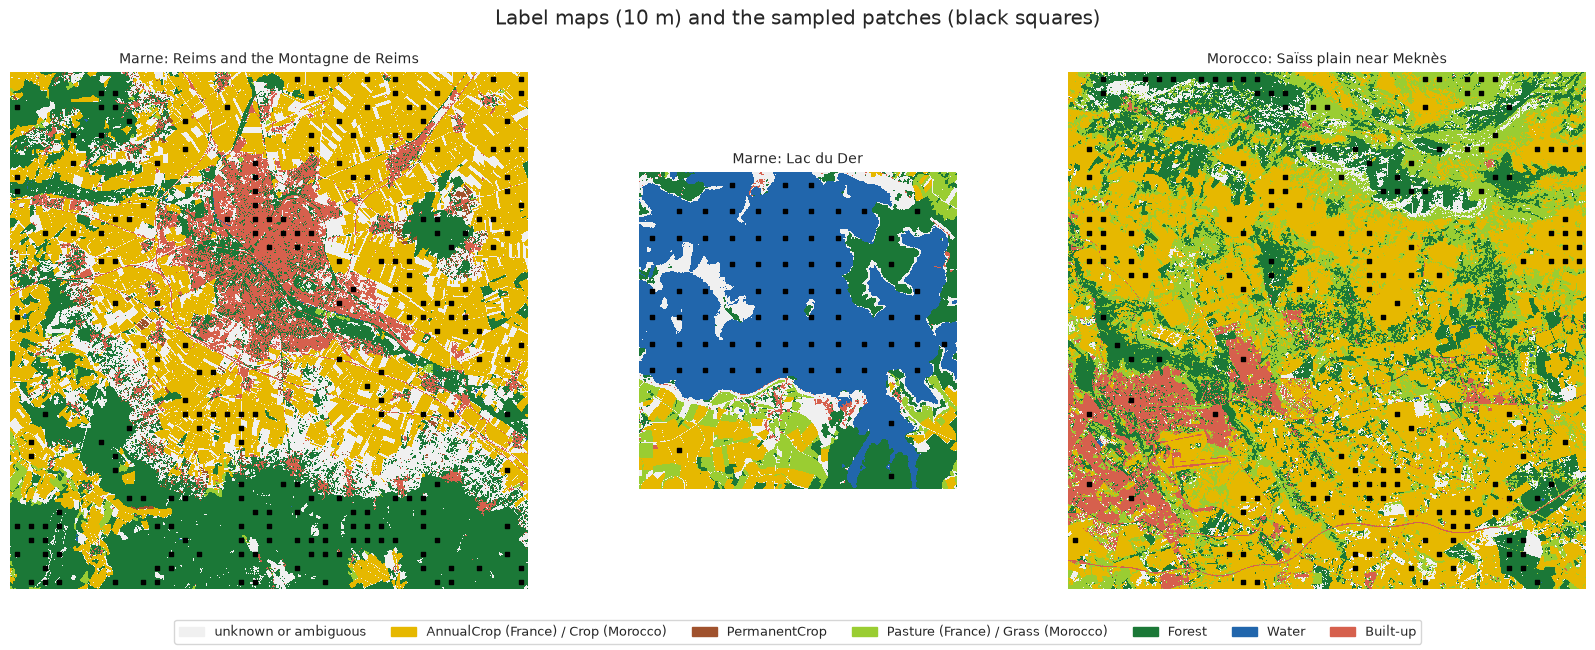

In [4]:
colors = {
    "AnnualCrop": "#e6b800", "PermanentCrop": "#a0522d", "Pasture": "#9acd32", "Crop": "#e6b800",
    "Grass": "#9acd32", "Forest": "#1b7837", "Water": "#2166ac", "Built-up": "#d6604d",
}  # fmt: skip
cmap = ListedColormap(["#f0f0f0"] + [colors[label] for label in LABELS])

fig, axes = plt.subplots(1, 3, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1, 0.45, 1]})
for ax, (key, grid) in zip(axes, grids.items()):
    ax.imshow(np.where(grid < 0, 0, grid + 1), cmap=cmap, vmin=0, vmax=len(LABELS), interpolation="nearest")
    chosen = patches[patches.region == key]
    ax.scatter(chosen.col * PATCH + PATCH / 2, chosen.row * PATCH + PATCH / 2, s=6, c="black", marker="s")
    ax.set_title(REGIONS[key].name, fontsize=10)
    ax.axis("off")
legend = [
    Patch(color="#f0f0f0", label="unknown or ambiguous"),
    Patch(color=colors["AnnualCrop"], label="AnnualCrop (France) / Crop (Morocco)"),
    Patch(color=colors["PermanentCrop"], label="PermanentCrop"),
    Patch(color=colors["Pasture"], label="Pasture (France) / Grass (Morocco)"),
] + [Patch(color=colors[label], label=label) for label in ["Forest", "Water", "Built-up"]]
fig.legend(handles=legend, loc="lower center", ncol=7, fontsize=9)
fig.suptitle("Label maps (10 m) and the sampled patches (black squares)")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(FIGURES_DIR / "realworld_label_maps.png", dpi=130)

**What it shows**

- 447 patches: 216 around Reims, 69 at Lac du Der (water), 162 near Meknès.
- South of Reims, the vineyards are white: they are not in the RPG. Built-up patches are rare, because
  buildings mix with trees.
- Much of the Moroccan plain is mapped as tree cover, mixed with cropland.

## 2. Dates

The least cloudy date of each season of 2025 whose images cover the whole region.

In [5]:
dates_path = save_path("dates.parquet")
if dates_path.exists():
    dates = pd.read_parquet(dates_path)
else:
    dates = pd.concat([best_dates(region).assign(region=key) for key, region in REGIONS.items()], ignore_index=True)
    dates.to_parquet(dates_path)
dates.pivot(index="region", columns="season", values="date")[SEASON_ORDER]

season,winter,spring,summer,autumn
region,,,,
lac_du_der,2025-01-14,2025-04-11,2025-06-13,2025-09-18
marne,2025-02-23,2025-04-29,2025-07-02,2025-09-28
morocco,2025-01-02,2025-05-19,2025-07-28,2025-10-24


## 3. Download and cut the patches

In [6]:
imagery = {}  # (region, season) -> {"l1c", "l2a": (n, 13, 64, 64) arrays, "bad_share", "snow_share"}
for row in dates.itertuples():
    region_patches = patches[patches.region == row.region].reset_index(drop=True)
    data = load_or_download(row.region, row.season, row.date, region_patches)
    assert len(data["l1c"]) == len(region_patches), "cache does not match the patches: delete data/interim/realworld/"
    imagery[(row.region, row.season)] = data
    usable = (data["bad_share"] <= MAX_BAD_SHARE).sum()
    snowy = (data["snow_share"] > 0).sum()
    print(f"{row.region:<11} {row.season:<7} {row.date}: {usable:>3} of {len(region_patches)} patches cloud-free, {snowy} with snow")

marne       winter  2025-02-23: 206 of 216 patches cloud-free, 0 with snow
marne       spring  2025-04-29: 215 of 216 patches cloud-free, 0 with snow
marne       summer  2025-07-02: 216 of 216 patches cloud-free, 0 with snow
marne       autumn  2025-09-28: 207 of 216 patches cloud-free, 0 with snow
lac_du_der  winter  2025-01-14:  24 of 69 patches cloud-free, 1 with snow
lac_du_der  spring  2025-04-11:  69 of 69 patches cloud-free, 0 with snow
lac_du_der  summer  2025-06-13:  69 of 69 patches cloud-free, 0 with snow
lac_du_der  autumn  2025-09-18:  43 of 69 patches cloud-free, 0 with snow
morocco     winter  2025-01-02: 162 of 162 patches cloud-free, 0 with snow
morocco     spring  2025-05-19: 162 of 162 patches cloud-free, 0 with snow
morocco     summer  2025-07-28: 162 of 162 patches cloud-free, 0 with snow
morocco     autumn  2025-10-24: 162 of 162 patches cloud-free, 0 with snow


## 4. What the new patches look like

The same patches through the four seasons (Level-1C).

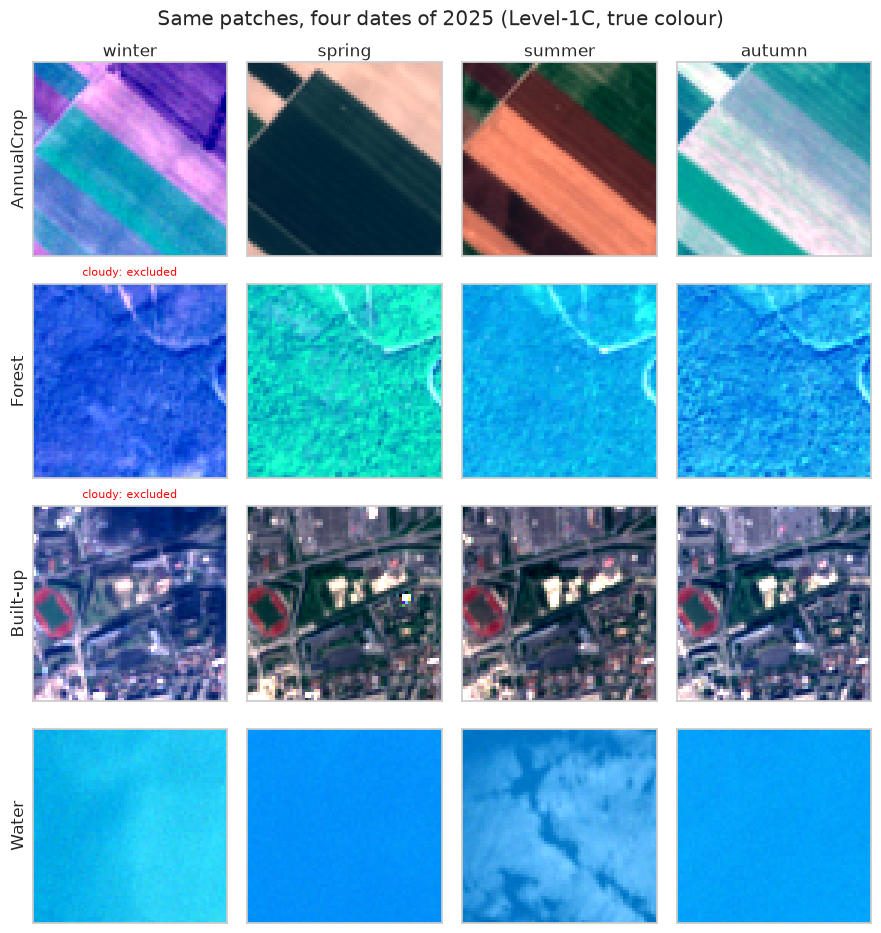

In [7]:
marne = patches[patches.region == "marne"].reset_index(drop=True)
lac = patches[patches.region == "lac_du_der"].reset_index(drop=True)
examples = [("marne", marne.index[marne.label == label][0], label) for label in ["AnnualCrop", "Forest", "Built-up"]]
examples.append(("lac_du_der", lac.index[lac.label == "Water"][0], "Water"))

fig, axes = plt.subplots(len(examples), 4, figsize=(9, 9.5))
for i, (region, idx, label) in enumerate(examples):
    for j, season in enumerate(SEASON_ORDER):
        data = imagery[(region, season)]
        axes[i, j].imshow(to_rgb(data["l1c"][idx]))
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
        if data["bad_share"][idx] > MAX_BAD_SHARE:
            axes[i, j].set_title("cloudy: excluded", fontsize=8, color="red")
        if i == 0:
            axes[i, j].set_xlabel(season)
            axes[i, j].xaxis.set_label_position("top")
    axes[i, 0].set_ylabel(label)
fig.suptitle("Same patches, four dates of 2025 (Level-1C, true colour)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_seasons.png", dpi=130)

Level-1C against Level-2A: the same patches and date, on one fixed colour scale.

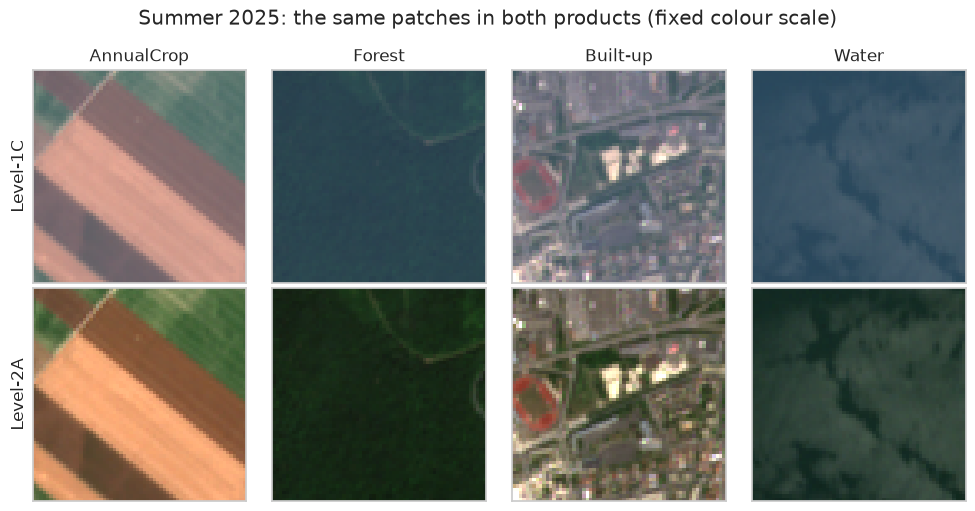

In [8]:
def fixed_rgb(patch, vmax=3000):
    return np.clip(np.stack([patch[EUROSAT_BANDS.index(b)] for b in ("B04", "B03", "B02")], axis=-1) / vmax, 0, 1)


fig, axes = plt.subplots(2, len(examples), figsize=(10, 5.2))
for j, (region, idx, label) in enumerate(examples):
    data = imagery[(region, "summer")]
    for i, product in enumerate(["l1c", "l2a"]):
        axes[i, j].imshow(fixed_rgb(data[product][idx]))
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
    axes[0, j].set_title(label)
axes[0, 0].set_ylabel("Level-1C")
axes[1, 0].set_ylabel("Level-2A")
fig.suptitle("Summer 2025: the same patches in both products (fixed colour scale)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_l1c_vs_l2a.png", dpi=130)

,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
EuroSAT train,1354.0,1118.0,1043.0,948.0,1199.0,2000.0,2369.0,2297.0,2594.0,732.0,12.0,1819.0,1119.0
"Marne summer, L1C",1451.0,1257.0,1236.0,1229.0,1506.0,2784.0,3454.0,3320.0,3861.0,686.0,12.0,2547.0,1420.0
"Marne summer, L2A",579.0,709.0,1041.0,1159.0,1676.0,3095.0,3665.0,3748.0,4005.0,3994.0,12.0,2844.0,1767.0
"Morocco summer, L1C",1508.0,1428.0,1556.0,1967.0,2187.0,2627.0,2921.0,2885.0,3202.0,1148.0,17.0,3481.0,2462.0


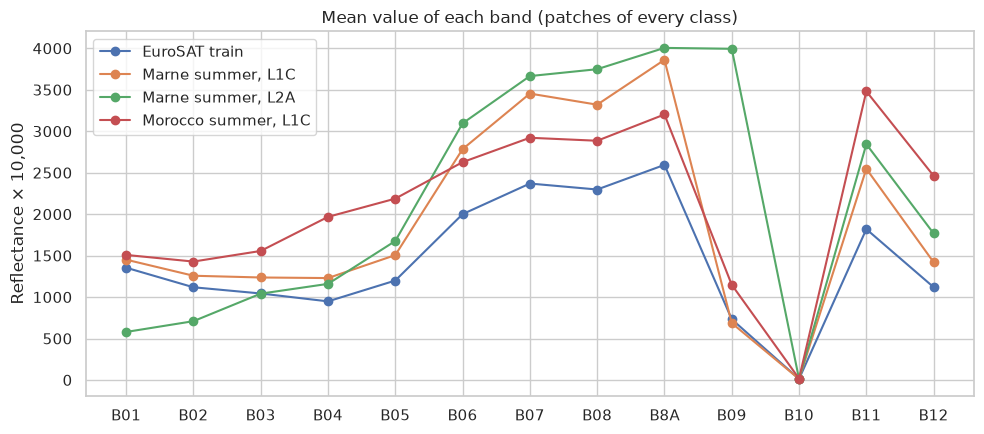

In [9]:
features = load_tile_features()
eurosat_means = features.loc[features.split == "train", [f"mean_{b}" for b in BANDS_BY_WAVELENGTH]].mean().to_numpy()


def band_means(region, season, product):
    data = imagery[(region, season)]
    ok = data["bad_share"] <= MAX_BAD_SHARE
    means = data[product][ok].mean(axis=(0, 2, 3))
    return [means[EUROSAT_BANDS.index(b)] for b in BANDS_BY_WAVELENGTH]


shift = pd.DataFrame(
    {
        "EuroSAT train": eurosat_means,
        "Marne summer, L1C": band_means("marne", "summer", "l1c"),
        "Marne summer, L2A": band_means("marne", "summer", "l2a"),
        "Morocco summer, L1C": band_means("morocco", "summer", "l1c"),
    },
    index=BANDS_BY_WAVELENGTH,
).round(0)
shift.plot(marker="o", figsize=(10, 4.5), title="Mean value of each band (patches of every class)")
plt.ylabel("Reflectance × 10,000")
plt.xticks(range(len(BANDS_BY_WAVELENGTH)), BANDS_BY_WAVELENGTH)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_band_shift.png", dpi=130)
shift.T

**What it shows**

- A field changes through the year: bare soil in winter and autumn, green in spring, harvested in summer.
- Level-2A removes the haze: on the same patches, blue (B02) drops from 1,257 to 709 and B09 jumps from 686
  to 3,994. Most of the values the model learned move.
- Moroccan patches are brighter in red and short-wave infrared: dry, bare soils. (The columns differ in class
  mix, except Level-1C and Level-2A, which hold the same patches.)

## 5. Predictions through the API

Each patch is sent three times: Level-1C, Level-2A (B10, absent from Level-2A, set to its EuroSAT mean), and
Level-2A with B09 also replaced, to test whether B09 causes the drop (R4). The EuroSAT test set goes through
the same API.

In [10]:
b09_eurosat = round(float(features.loc[features.split == "train", "mean_B09"].mean()))


def versions(data):
    fixed = data["l2a"].copy()
    fixed[:, EUROSAT_BANDS.index("B09")] = b09_eurosat
    return {"L1C": data["l1c"], "L2A": data["l2a"], "L2A, B09 replaced": fixed}


predictions_path = save_path("predictions.parquet")
if predictions_path.exists():
    preds = pd.read_parquet(predictions_path)
else:
    frames = []
    for (region, season), data in imagery.items():
        region_patches = patches[patches.region == region].reset_index(drop=True)
        usable = data["bad_share"] <= MAX_BAD_SHARE
        if not usable.any():
            print(f"{region:<11} {season:<7} no cloud-free patch")
            continue
        for product, array in versions(data).items():
            probs = classify(array[usable])
            frame = region_patches.loc[usable].copy()
            frame["idx"] = np.flatnonzero(usable)
            frame["season"], frame["product"] = season, product
            frame["snow_share"] = data["snow_share"][usable]
            frame["pred"] = [EUROSAT_CLASSES[i] for i in probs.argmax(axis=1)]
            frame["prob"] = probs.max(axis=1)
            frames.append(frame)
        print(f"{region:<11} {season:<7} done")
    preds = pd.concat(frames, ignore_index=True)
    preds.to_parquet(predictions_path)

preds["pred_group"] = preds["pred"].map(EUROSAT_TO_GROUP)
preds["correct"] = preds["pred_group"] == preds["group"]
print(len(preds), "predictions")

marne       winter  done
marne       spring  done
marne       summer  done
marne       autumn  done
lac_du_der  winter  done
lac_du_der  spring  done
lac_du_der  summer  done
lac_du_der  autumn  done
morocco     winter  done
morocco     spring  done
morocco     summer  done
morocco     autumn  done
5091 predictions


In [11]:
eurosat_path = save_path("eurosat_test_predictions.parquet")
if eurosat_path.exists():
    eurosat_preds = pd.read_parquet(eurosat_path)
else:
    test = features[features.split == "test"]
    probs = classify_files(test["path"].tolist())
    eurosat_preds = pd.DataFrame({"label": test["class"].to_numpy(), "pred": [EUROSAT_CLASSES[i] for i in probs.argmax(axis=1)]})
    eurosat_preds.to_parquet(eurosat_path)
eurosat_preds["group"] = eurosat_preds["label"].map(EUROSAT_TO_GROUP)
eurosat_preds["pred_group"] = eurosat_preds["pred"].map(EUROSAT_TO_GROUP)
eurosat_preds["correct"] = eurosat_preds["group"] == eurosat_preds["pred_group"]
print(f"EuroSAT test set through the API: {(eurosat_preds.label == eurosat_preds.pred).mean():.4f} (10 classes), "
      f"{eurosat_preds.correct.mean():.4f} (5 groups)")

EuroSAT test set through the API: 0.9898 (10 classes), 0.9946 (5 groups)


## 6. Results

### The ladder

Balanced accuracy: the mean recall of the groups present, so that the largest groups do not dominate.

,balanced_accuracy,low,high,accuracy,patches
test,,,,,
0 · EuroSAT test set,0.994,0.992,0.996,0.995,5400
"1 · Marne, summer, L1C",0.966,0.949,0.982,0.951,285
"2 · Marne, spring, L1C",0.966,0.948,0.982,0.951,284
"2 · Marne, autumn, L1C",0.955,0.935,0.973,0.928,250
"2 · Marne, winter, L1C",0.937,0.913,0.959,0.891,230
"3 · Marne, summer, L2A",0.446,0.421,0.468,0.512,285
"3 · Marne, summer, L2A with B09 replaced",0.569,0.508,0.637,0.575,285
"4 · Morocco, summer, L1C",0.716,0.674,0.741,0.698,162


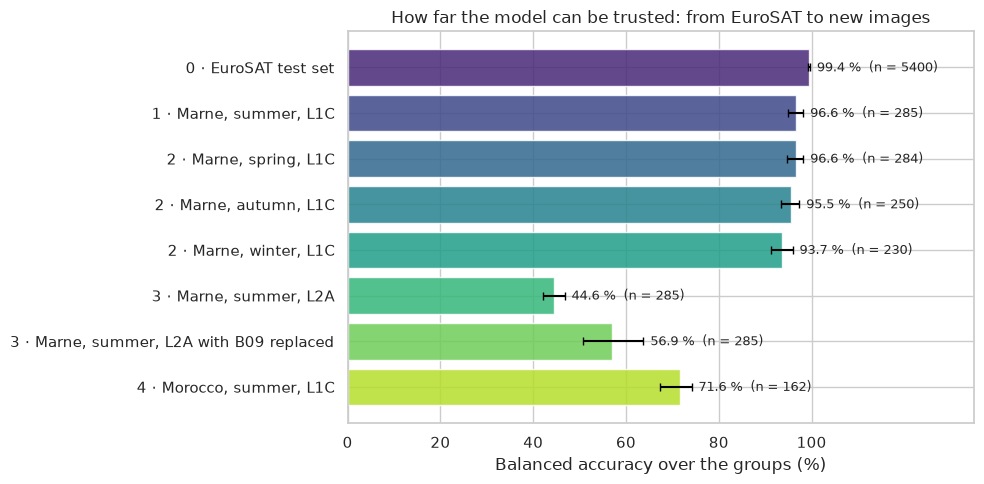

In [12]:
def balanced_accuracy(df):
    return df.groupby("group")["correct"].mean().mean()


def bootstrap_ci(df, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    values = [balanced_accuracy(df.iloc[rng.integers(0, len(df), len(df))]) for _ in range(n)]
    return np.percentile(values, [2.5, 97.5])


france = preds[preds.region.isin(["marne", "lac_du_der"])]
morocco = preds[preds.region == "morocco"]


def select(df, season, product):
    return df[(df.season == season) & (df["product"] == product)]


ladder = {
    "0 · EuroSAT test set": eurosat_preds,
    "1 · Marne, summer, L1C": select(france, "summer", "L1C"),
    "2 · Marne, spring, L1C": select(france, "spring", "L1C"),
    "2 · Marne, autumn, L1C": select(france, "autumn", "L1C"),
    "2 · Marne, winter, L1C": select(france, "winter", "L1C"),
    "3 · Marne, summer, L2A": select(france, "summer", "L2A"),
    "3 · Marne, summer, L2A with B09 replaced": select(france, "summer", "L2A, B09 replaced"),
    "4 · Morocco, summer, L1C": select(morocco, "summer", "L1C"),
}
rows = []
for name, df in ladder.items():
    low, high = bootstrap_ci(df)
    rows.append({"test": name, "balanced_accuracy": balanced_accuracy(df), "low": low, "high": high,
                 "accuracy": df["correct"].mean(), "patches": len(df)})
ladder_table = pd.DataFrame(rows).set_index("test")

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(ladder_table))[::-1]
values = ladder_table["balanced_accuracy"] * 100
ax.barh(y, values, color=sns.color_palette("viridis", len(ladder_table)), alpha=0.85)
ax.errorbar(values, y, xerr=[values - ladder_table["low"] * 100, ladder_table["high"] * 100 - values], fmt="none", color="black", capsize=3)
for yi, v, high, n in zip(y, values, ladder_table["high"] * 100, ladder_table["patches"]):
    ax.text(high + 1.5, yi, f"{v:.1f} %  (n = {n})", va="center", fontsize=9)  # right of the error bar
ax.set_yticks(y, ladder_table.index)
ax.set_xlim(0, 135)  # room for the labels right of the bars
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Balanced accuracy over the groups (%)")
ax.set_title("How far the model can be trusted: from EuroSAT to new images")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_ladder.png", dpi=150)
ladder_table.style.format({"balanced_accuracy": "{:.3f}", "low": "{:.3f}", "high": "{:.3f}", "accuracy": "{:.3f}"})

**What it shows**

- A new date costs 3 points (96.6 %), the seasons up to 6 (93.7 % in winter).
- Level-2A halves the score (44.6 %); replacing B09 recovers only a quarter of the gap.
- Morocco: 71.6 %, mostly because of one group, Forest (see below).

### Every region, season and product

In [13]:
table = preds.groupby(["region", "product", "season"]).apply(balanced_accuracy, include_groups=False).unstack()[SEASON_ORDER]
table.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.3, vmax=1.0)

**What it shows**

- Level-1C holds in every French season (93.7 to 96.6 %). Level-2A fails everywhere (22.7 to 49.8 %), and
  still with B09 replaced (45 to 57 %).

### Seasons: which class drops?

In [14]:
france_l1c = france[france["product"] == "L1C"]
recall = france_l1c.groupby(["label", "season"])["correct"].agg(["mean", "size"]).unstack()
recall_table = recall["mean"][SEASON_ORDER].round(3).astype(str) + " (n=" + recall["size"][SEASON_ORDER].astype(str) + ")"
recall_table

season,winter,spring,summer,autumn
label,,,,
AnnualCrop,0.879 (n=99),0.97 (n=100),0.98 (n=101),0.871 (n=101)
Built-up,1.0 (n=13),1.0 (n=16),1.0 (n=16),1.0 (n=16)
Forest,0.867 (n=98),0.894 (n=104),0.885 (n=104),0.947 (n=95)
Water,1.0 (n=20),1.0 (n=64),1.0 (n=64),1.0 (n=38)


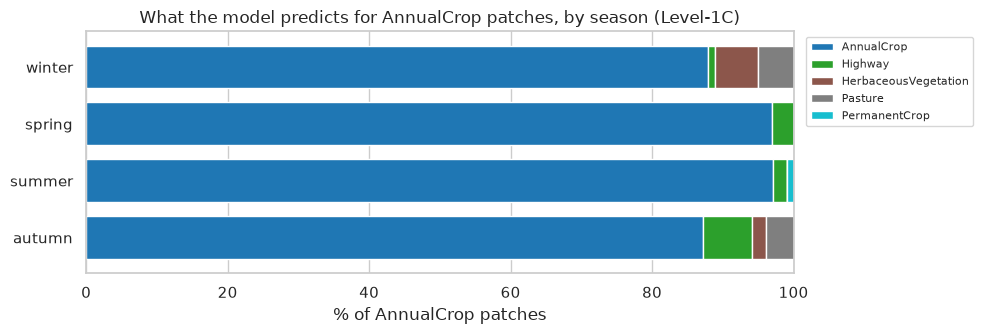

In [15]:
crop = france_l1c[france_l1c.label == "AnnualCrop"]
shares = pd.crosstab(crop["season"], crop["pred"], normalize="index").reindex(SEASON_ORDER) * 100
shares = shares[shares.max().sort_values(ascending=False).index]
ax = shares.plot.barh(stacked=True, figsize=(10, 3.5), colormap="tab10", width=0.75)
ax.invert_yaxis()
ax.set_xlabel("% of AnnualCrop patches")
ax.set_ylabel("")
ax.set_title("What the model predicts for AnnualCrop patches, by season (Level-1C)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_annualcrop_seasons.png", dpi=130)

**What it shows**

- AnnualCrop drops to 87–88 % in autumn and winter, when fields are bare; Forest to 87 % in winter, when
  trees are leafless.
- Built-up and Water are right at every date.
- The guess before running (AnnualCrop below 60 % in winter) was far off: EuroSAT already contains bare
  fields.

### Level-2A: what changes?

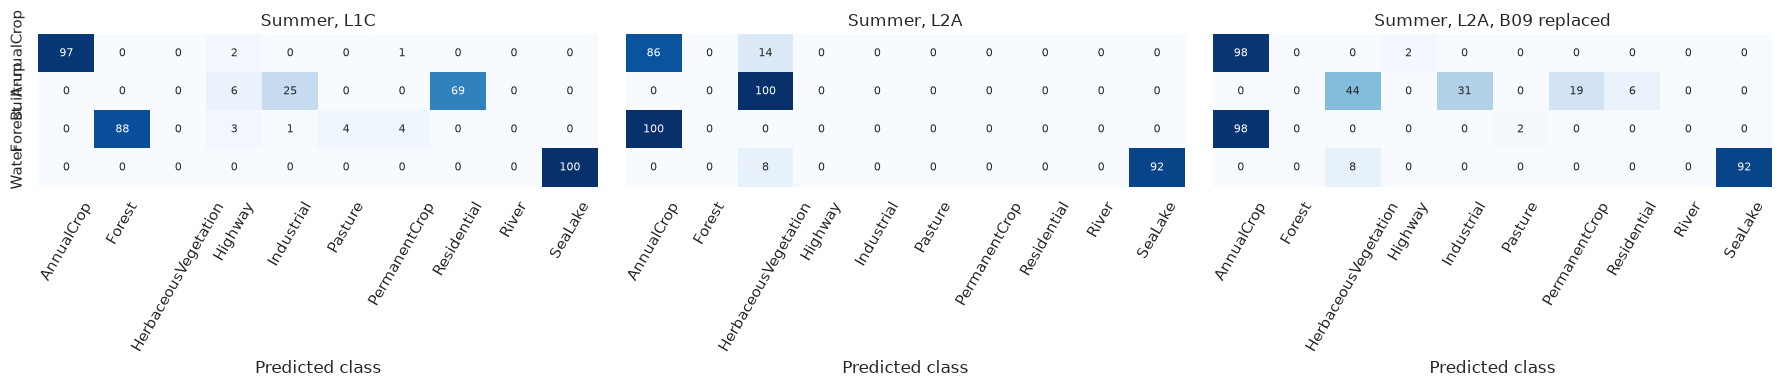

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
summer = france[france.season == "summer"]
for ax, product in zip(axes, ["L1C", "L2A", "L2A, B09 replaced"]):
    df = summer[summer["product"] == product]
    table = pd.crosstab(df["label"], df["pred"], normalize="index").reindex(columns=EUROSAT_CLASSES, fill_value=0) * 100
    sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Summer, {product}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=60)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_l2a_confusion.png", dpi=130)

**What it shows**

- In Level-2A, all 104 forest patches become AnnualCrop, and all 16 built-up patches become
  HerbaceousVegetation.
- Replacing B09 fixes AnnualCrop but not Forest. Without the haze, forest is darker and greener in the
  visible bands, which this model reads as a crop field.

### Morocco

season
winter    0.669
spring    0.635
summer    0.716
autumn    0.725
dtype: float64

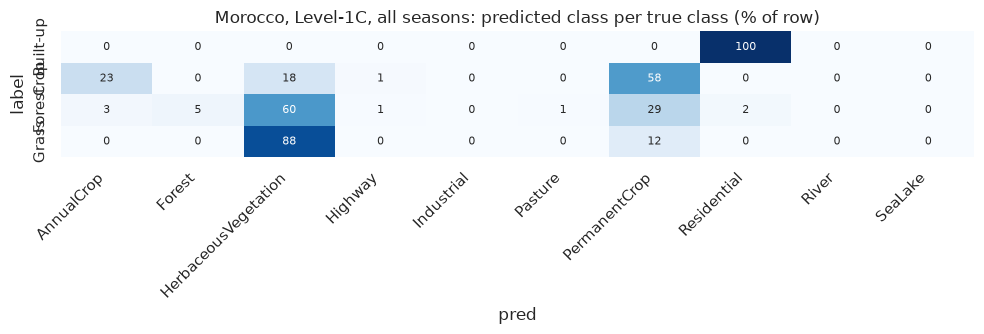

In [17]:
morocco_l1c = morocco[morocco["product"] == "L1C"]
table = pd.crosstab(morocco_l1c["label"], morocco_l1c["pred"], normalize="index").reindex(columns=EUROSAT_CLASSES, fill_value=0) * 100
plt.figure(figsize=(10, 4))
sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, annot_kws={"size": 8})
plt.title("Morocco, Level-1C, all seasons: predicted class per true class (% of row)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.ylabel("True class")
plt.xlabel("Predicted class")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_morocco.png", dpi=130)
morocco_l1c.groupby("season").apply(balanced_accuracy, include_groups=False).reindex(SEASON_ORDER).round(3)

**What it shows**

- Crop (81 % right), Grass and Built-up behave as in France.
- "Forest" is predicted as Forest in only 5 % of cases, mostly as HerbaceousVegetation or PermanentCrop.
  These patches are orchards and scattered trees, which WorldCover counts as tree cover: the model is
  usually closer to the ground than the label.
- Without the Forest group: 95.4 % in summer.
- Confidence no longer flags errors (about 90 %, right or wrong), whereas in France a 90 % threshold catches
  44 of the 71 errors.

### Errors

Twelve random Level-1C errors.

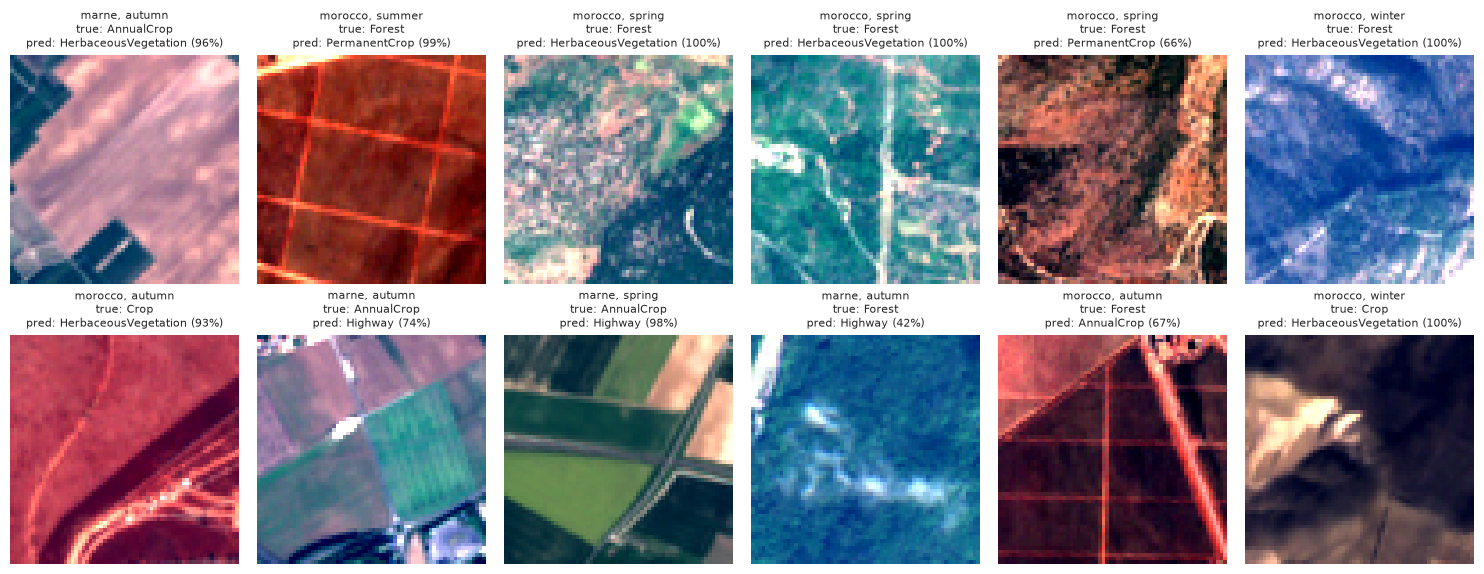

In [18]:
l1c_errors = preds[(preds["product"] == "L1C") & ~preds["correct"]]
errors = l1c_errors.sample(min(12, len(l1c_errors)), random_state=0)
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, row in zip(axes.flat, errors.itertuples()):
    ax.imshow(to_rgb(imagery[(row.region, row.season)]["l1c"][row.idx]))
    ax.set_title(f"{row.region}, {row.season}\ntrue: {row.label}\npred: {row.pred} ({row.prob:.0%})", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "realworld_errors.png", dpi=130)

**What it shows**

- Definition mismatches (Moroccan plantations labelled Forest), mixed patches (a road across a field),
  missed clouds, and some plain model errors.
- Fewer than half look like plain model mistakes; a manual review would put a number on it.

## 7. Hypotheses: verdict

| ID | Hypothesis | Evidence | Verdict |
|---|---|---|---|
| R1 | At least 90 % on a new date. | 96.6 % | **Confirmed** |
| R2 | Winter is hardest, because of AnnualCrop. | Winter is lowest (93.7 %), but Forest drops as much as AnnualCrop | **Partly** |
| R3 | Level-2A costs at least 10 points. | −52 points | **Confirmed** |
| R4 | B09 explains at least half of the Level-2A drop. | 24 % in France, 55 % in Morocco | **Refuted in France** |
| R5 | Morocco is at least 15 points lower. | −25 points; −4 without Forest | **Confirmed, but mostly a label effect** |

## 8. What affected these results

| Factor | Effect |
|---|---|
| Definition mismatch (tree cover against Forest) | Lowers Morocco by about 24 points |
| Map errors, mixed patches, missed clouds | Lower the scores, by an unmeasured amount |
| Scoring by 5 groups | Raises them: AnnualCrop–PermanentCrop confusions count as right |
| Small groups (Built-up, Grass) | Uncertain scores |
| One region and one day per season | A season's result includes that day's weather |

## 9. Conclusion

- **Usable:** Level-1C images of European landscapes, in every season (above 93 %). In France, answers below
  90 % confidence deserve a check.
- **Not usable:** Level-2A images, the most common product, and landscapes EuroSAT does not contain, such as
  orchards with scattered trees.
- **For the API:** Level-2A input is now rejected (section 10).

## 10. Improving Level-2A support

| Option | Idea | Limit |
|---|---|---|
| **1. Detect and reject Level-2A** | The API refuses tiles whose B10 is constant (Level-2A has no B10) or whose B01 is below 0.85 × B02 (haze keeps B01 higher in Level-1C). | No predictions for Level-2A |
| 2. Convert Level-2A to "pseudo-Level-1C" | Fit a per-band conversion on the paired patches of this notebook, apply it before the model. | Haze varies with date and place, so the conversion may not transfer |
| 3. Atmospheric augmentation | Vary the brightness of each band at random during training, so the model relies less on haze. | Level-2A shifts are not random; the gain is uncertain |
| 4. Train on Level-2A | Download the 27,000 EuroSAT locations again as Level-2A and fine-tune. | The labels date from 2015–2017; some places have changed |

**Decision: option 1 only, then part 2.** The check is now in the API (`check_level_1c` in `api/main.py`).
Sent through the API, it rejected all 1,697 Level-2A patches of this notebook and none of the 1,697
Level-1C patches or 3,000 EuroSAT tiles. The B01 rule alone catches 69 % of Level-2A patches, for senders
who fill B10 with varying values.

Options 2 to 4 are left for later. Part 2, the core of the project, works on Level-2A NDVI time series and
does not depend on this classifier.